# 04 — BTV0125 beam parameters

Classic image processing on the screen camera, one row per shot:
**amplitude** (peak), **intensity** (sum), **mean x / mean y** (centroid) and **sigma x / sigma y** (RMS size), in mm.

Steps for each image:
1. crop a region of interest (ROI) around the beam
2. subtract the background (median of the top rows of the image, far from the beam)
3. 3×3 median filter to remove single-pixel hits (hot pixels up to 4095 counts)
4. **amplitude** = peak of a lightly smoothed copy (Gaussian, σ = 3 px): small clusters of hits get spread out, the beam (σ ≈ 26 px) doesn't
5. beam mask = the largest connected blob above `THRESHOLD` × amplitude — this drops hit clusters anywhere else in the image.
   The beam has a wide faint halo, so the RMS size depends strongly on this cut (~1.7 mm with no cut, ~0.28 mm at 5%, ~0.14 mm at 20%)
6. moments inside the mask: centroid and RMS size

In [1]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Ellipse
from scipy import ndimage

DATA_DIR = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
files = sorted(DATA_DIR.glob("chunk_*.h5"))

ROI = (slice(350, 1150), slice(600, 1450))  # rows, cols — beam moves within rows ~640–830, cols ~930–1160
BG_ROWS = slice(0, 150)                     # top rows of the full image, no beam there
THRESHOLD = 0.05                            # keep pixels above 5% of the peak

In [2]:
# pixel -> mm axes (same for every shot; some shots have an empty axis, so take the first non-empty one)
def first_non_empty(obj):
    arrays = [obj[k][:] for k in sorted(obj)] if isinstance(obj, h5py.Group) else obj[:]
    return next(a for a in arrays if a.size)


with h5py.File(files[0], "r") as f:
    x_mm_full = first_non_empty(f["BTV0125/imagePositionSet1"])
    y_mm_full = first_non_empty(f["BTV0125/imagePositionSet2"])

x_mm, y_mm = x_mm_full[ROI[1]], y_mm_full[ROI[0]]
print(f"pixel size {abs(x_mm[1] - x_mm[0]):.4f} mm | ROI x {x_mm[0]:.2f}…{x_mm[-1]:.2f} mm, y {y_mm[0]:.2f}…{y_mm[-1]:.2f} mm")

pixel size 0.0107 mm | ROI x 3.55…12.64 mm, y 2.76…-5.79 mm


In [3]:
def clean_image(raw):
    """Background-subtracted, hot-pixel-filtered ROI."""
    raw = raw.astype(np.float32)
    background = np.median(raw[BG_ROWS])
    return ndimage.median_filter(raw[ROI], size=3) - background


def beam_mask(img):
    """Largest connected region above THRESHOLD × peak of the smoothed image, and that peak."""
    smooth = ndimage.gaussian_filter(img, 3)
    peak = smooth.max()
    labels, _ = ndimage.label(smooth > THRESHOLD * peak)
    largest = np.bincount(labels.ravel())[1:].argmax() + 1
    return labels == largest, peak


def beam_params(raw):
    img = clean_image(raw)
    mask, peak = beam_mask(img)
    img = img * mask
    total = img.sum()
    proj_x, proj_y = img.sum(axis=0), img.sum(axis=1)
    mean_x = proj_x @ x_mm / total
    mean_y = proj_y @ y_mm / total
    return {
        "amplitude": peak,
        "intensity": total,
        "mean_x": mean_x,
        "mean_y": mean_y,
        "sigma_x": np.sqrt(proj_x @ (x_mm - mean_x) ** 2 / total),
        "sigma_y": np.sqrt(proj_y @ (y_mm - mean_y) ** 2 / total),
    }

## Check on one shot

{'amplitude': 756.328, 'intensity': 2288212.0, 'mean_x': 7.031, 'mean_y': -0.476, 'sigma_x': 0.289, 'sigma_y': 0.309}


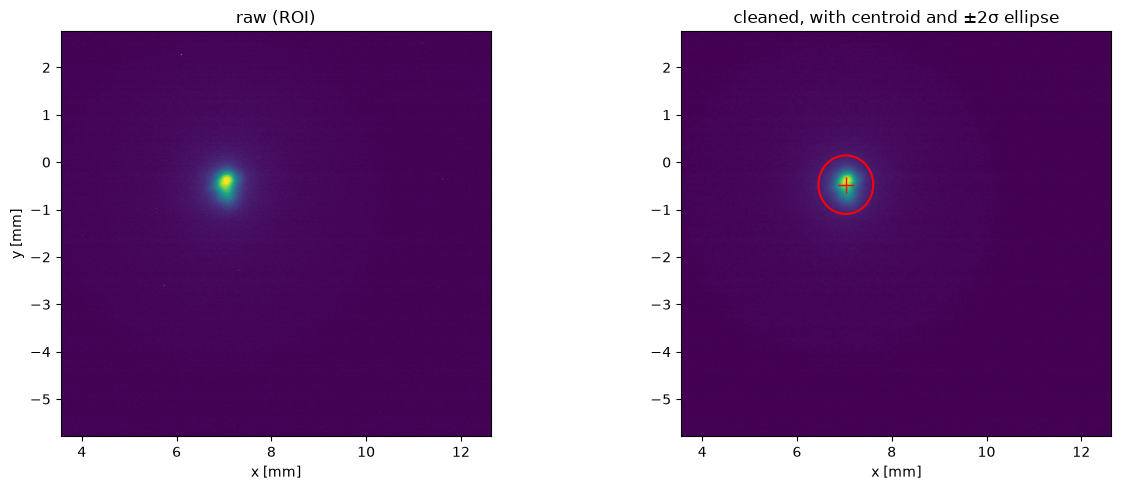

In [4]:
with h5py.File(files[0], "r") as f:
    raw = f["BTV0125/image2D"][0]

p = beam_params(raw)
print({k: round(float(v), 3) for k, v in p.items()})

extent = [x_mm[0], x_mm[-1], y_mm[-1], y_mm[0]]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(raw[ROI], extent=extent, vmax=np.percentile(raw[ROI], 99.99))
axes[0].set(title="raw (ROI)", xlabel="x [mm]", ylabel="y [mm]")
axes[1].imshow(clean_image(raw), extent=extent)
axes[1].add_patch(Ellipse((p["mean_x"], p["mean_y"]), 4 * p["sigma_x"], 4 * p["sigma_y"], fill=False, color="red", lw=1.5))
axes[1].plot(p["mean_x"], p["mean_y"], "r+", ms=12)
axes[1].set(title="cleaned, with centroid and ±2σ ellipse", xlabel="x [mm]")
fig.tight_layout()

## All shots (~2–3 min)

In [5]:
rows = []
for path in files:
    with h5py.File(path, "r") as f:
        btv = f["BTV0125"]
        image_number = btv["imageNumber"][:]
        for i in range(len(image_number)):
            rows.append({"chunk": path.stem, "image_number": image_number[i], **beam_params(btv["image2D"][i])})

btv_params = pd.DataFrame(rows)
btv_params["frozen"] = btv_params["image_number"].diff().eq(0)  # camera repeated its previous image

out = DATA_DIR.parent / "outputs" / "btv0125_params.csv"
out.parent.mkdir(exist_ok=True)
btv_params.to_csv(out, index_label="shot")
print(f"saved {len(btv_params)} shots to {out} | frozen images: {btv_params['frozen'].sum()}")
btv_params.describe().T

saved 2100 shots to /Users/angilard/Desktop/Fast-Approximate/outputs/btv0125_params.csv | frozen images: 1


,count,mean,std,min,25%,50%,75%,max
image_number,2100.0,9.791500e+03,606.361279,8.743000e+03,9.266750e+03,9.791500e+03,1.031625e+04,1.084100e+04
amplitude,2100.0,8.340627e+02,59.567860,6.521946e+02,7.963254e+02,8.290831e+02,8.659270e+02,1.237204e+03
intensity,2100.0,2.469825e+06,150493.859375,1.910364e+06,2.368843e+06,2.468918e+06,2.575304e+06,2.940290e+06
mean_x,2100.0,7.121786e+00,0.033518,6.878888e+00,7.103790e+00,7.123170e+00,7.140215e+00,7.289146e+00
mean_y,2100.0,-5.231142e-01,0.040273,-7.290185e-01,-5.477698e-01,-5.253236e-01,-5.013221e-01,-3.307038e-01
sigma_x,2100.0,2.862254e-01,0.010294,2.203812e-01,2.812356e-01,2.866353e-01,2.923498e-01,3.282277e-01
sigma_y,2100.0,3.126787e-01,0.014460,2.082998e-01,3.059191e-01,3.137417e-01,3.211016e-01,3.669421e-01


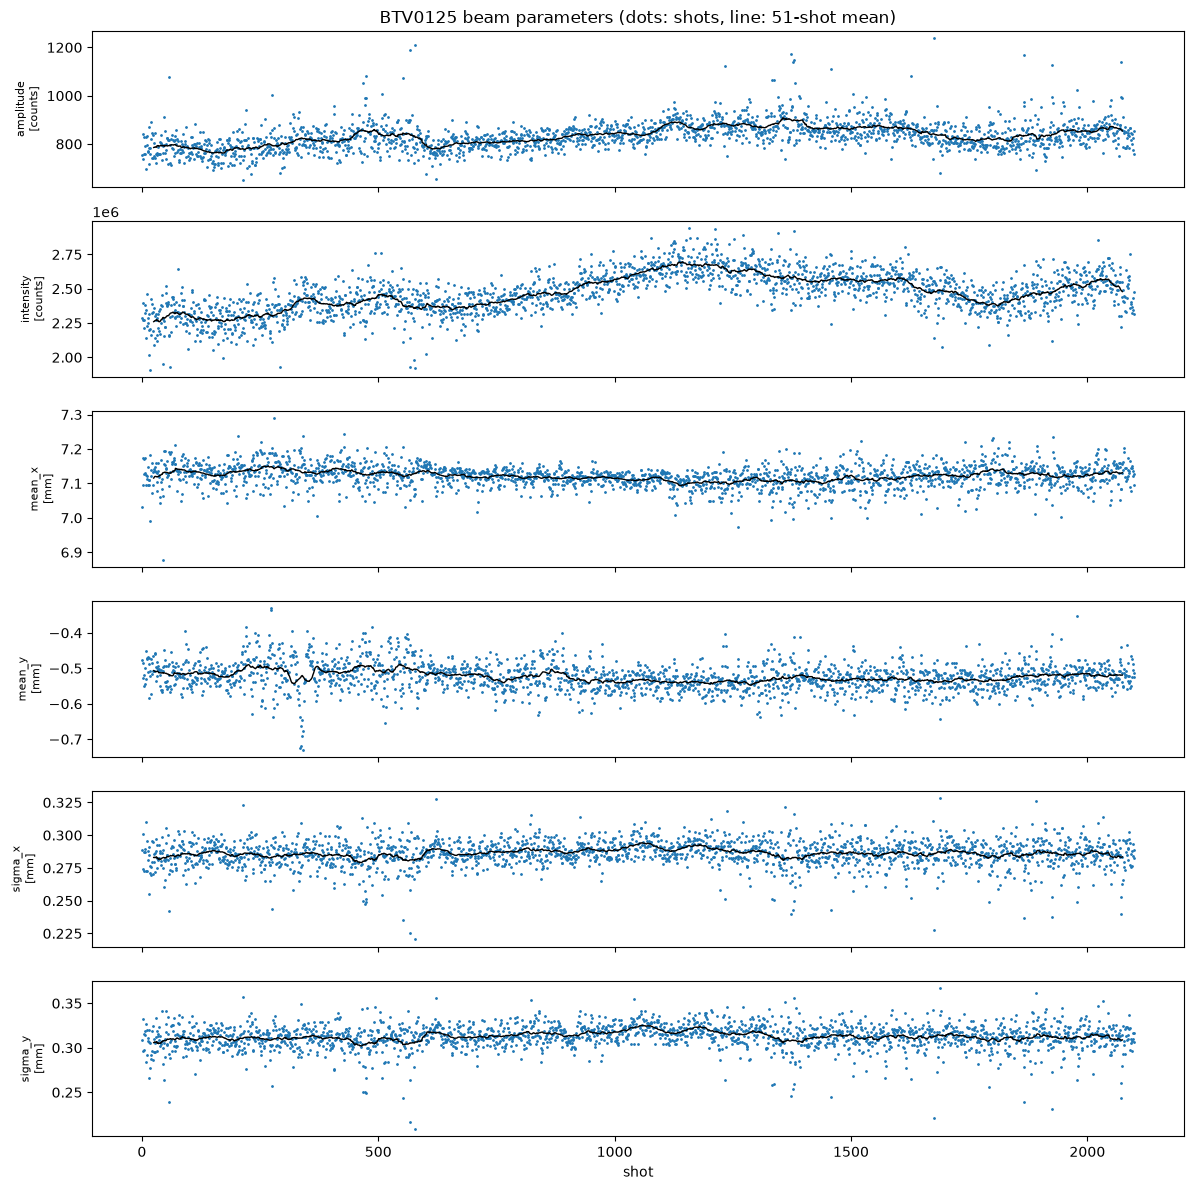

In [6]:
cols = ["amplitude", "intensity", "mean_x", "mean_y", "sigma_x", "sigma_y"]
units = {"mean_x": "mm", "mean_y": "mm", "sigma_x": "mm", "sigma_y": "mm", "amplitude": "counts", "intensity": "counts"}
ok = ~btv_params["frozen"]

fig, axes = plt.subplots(len(cols), 1, figsize=(12, 2 * len(cols)), sharex=True)
for ax, c in zip(axes, cols):
    ax.plot(btv_params.index[ok], btv_params.loc[ok, c], ".", ms=2)
    ax.plot(btv_params[c].rolling(51, center=True).mean(), "k", lw=1)
    ax.set_ylabel(f"{c}\n[{units[c]}]", fontsize=8)
axes[-1].set_xlabel("shot")
axes[0].set_title("BTV0125 beam parameters (dots: shots, line: 51-shot mean)")
fig.tight_layout()

## BTV0125 vs laser

Two laser measurements: `laser_amp` (matched filter on the `laser_scope` trace, as in notebook 03) and `lab_laser_power`.

Before correlating:
- the laser is stored **one row later** than the camera, so `laser[i + 1]` is paired with `BTV[i]`
- shots where the scope froze (repeated its previous trace) or the camera froze are dropped

**Overall** r includes the slow drift over the run; **shot-to-shot** r removes it (51-shot rolling mean).

In [7]:
def load(key):
    return np.concatenate([h5py.File(path, "r")[key][:] for path in files])


signal = load("laser_scope/signal")
t = h5py.File(files[0], "r")["laser_scope/times"][0]
clean = signal - signal[:, t < 5].mean(axis=1, keepdims=True)
template = clean.mean(axis=0) * ((t > 5.6) & (t < 39.8))
scope_frozen = np.r_[False, np.all(signal[1:] == signal[:-1], axis=1)]

laser = pd.DataFrame({
    "laser_amp": clean @ template / (template @ template),
    "lab_laser_power": load("lab_laser_power"),
}).shift(-1)                                                   # row i <- laser from row i + 1
scope_frozen = pd.Series(scope_frozen).shift(-1, fill_value=False).to_numpy()

BTV_COLS = ["amplitude", "intensity", "mean_x", "mean_y", "sigma_x", "sigma_y"]
both = pd.concat([btv_params[BTV_COLS], laser], axis=1)
keep = ~scope_frozen & ~btv_params["frozen"].to_numpy() & both.notna().all(axis=1).to_numpy()
both = both[keep]
print(f"kept {keep.sum()} / {len(keep)} shots")


def detrend(x, k=51):
    return x - x.rolling(k, center=True, min_periods=1).mean()


r_table = pd.DataFrame({
    f"{las} {kind}": [d[c].corr(d[las]) for c in BTV_COLS]
    for las in laser.columns
    for kind, d in [("overall", both), ("shot-to-shot", both.apply(detrend))]
}, index=BTV_COLS)
r_table.round(2)

kept 1615 / 2100 shots


,laser_amp overall,laser_amp shot-to-shot,lab_laser_power overall,lab_laser_power shot-to-shot
amplitude,0.49,0.18,0.60,0.37
intensity,0.76,0.44,0.87,0.68
mean_x,-0.23,-0.02,-0.25,-0.03
mean_y,-0.22,-0.09,-0.19,-0.02
sigma_x,0.13,0.09,0.11,0.04
sigma_y,0.16,0.09,0.16,0.06


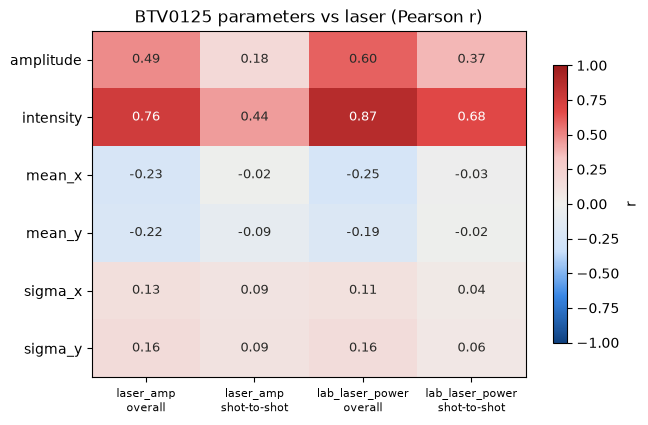

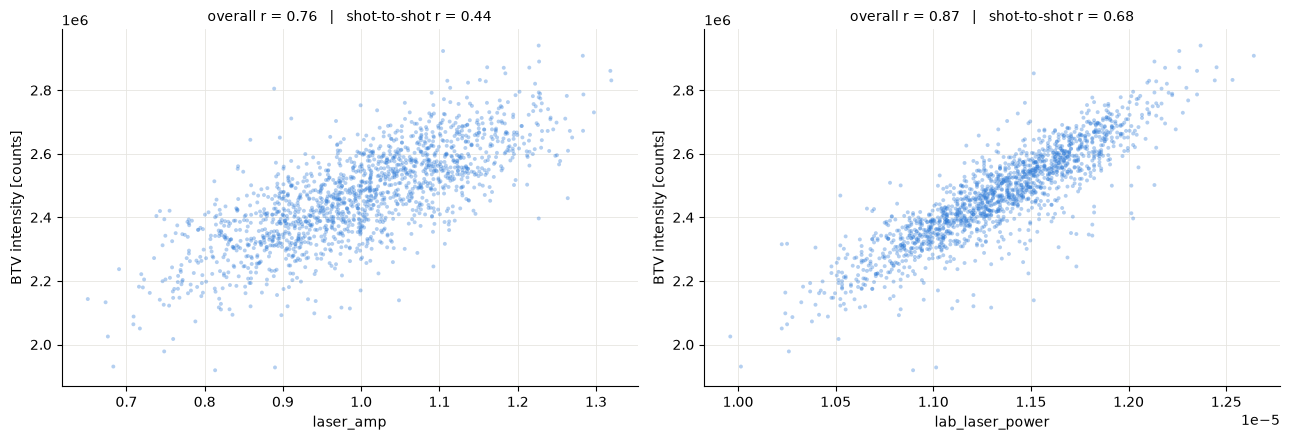

In [8]:
DIVERGING = LinearSegmentedColormap.from_list("div", ["#104281", "#3987e5", "#cde2fb", "#f0efec", "#f6c6c5", "#e34948", "#9b1c1c"])

fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(r_table, cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
for (i, j), r in np.ndenumerate(r_table.to_numpy()):
    ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=9, color="white" if abs(r) > 0.6 else "#2b2b29")
ax.set_xticks(range(r_table.shape[1]), [c.replace(" ", "\n") for c in r_table.columns], fontsize=8)
ax.set_yticks(range(len(BTV_COLS)), BTV_COLS)
ax.set_title("BTV0125 parameters vs laser (Pearson r)")
fig.colorbar(im, ax=ax, shrink=0.8, label="r");

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, las in zip(axes, laser.columns):
    ax.scatter(both[las], both["intensity"], s=8, color="#2a78d6", alpha=0.35, edgecolors="none")
    ax.set(xlabel=las, ylabel="BTV intensity [counts]",
           title=f"overall r = {r_table.loc['intensity', las + ' overall']:.2f}   |   "
                 f"shot-to-shot r = {r_table.loc['intensity', las + ' shot-to-shot']:.2f}")
    ax.title.set_fontsize(10)
    ax.grid(color="#e6e5e1", lw=0.6)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
fig.tight_layout()